# Apple Leaf Disease Detection Using Transfer Learning — Pretrained GoogLeNet Inference

**Paper:** Wani, Z.A., Zahoor, U., Shah, Z.A. *Apple Leaf Disease Detection Using Transfer Learning*, Annals of Data Science 12(1):213–222 (2024). DOI: [10.1007/s40745-024-00555-y](https://doi.org/10.1007/s40745-024-00555-y)

**Author code:** https://github.com/ozair-wani/Apple-leaf-disease-detection pinned at commit `947dae59b4e1d053b4235b0fae1823d51fbf85d4` (MIT License).

**Scope (partial demonstration):** We run the repository's own **pretrained inference path** — the saved best GoogLeNet checkpoint `t_googlenet.pth` with the exact preprocessing of `webapp.py` — over the author-bundled test split `webapp and code/Dataset/test` (4 classes), and report per-sample predictions, per-class accuracy and a confusion matrix. Training (the scripted 25-epoch fine-tune) and the Flask/Android deployment are **out of scope**.

**Execution status:** Executed and validated on a fresh Google Colab CPU runtime (see final report). Full paper text was unavailable through authorized routes (Springer challenge pages), so paper-reported accuracy numbers could not be quoted here; all evaluation values come from this executed run.

**日本語:** 論文「Apple Leaf Disease Detection Using Transfer Learning」の著者公開リポジトリ（MIT）に含まれる学習済みGoogLeNetチェックポイント `t_googlenet.pth` を、`webapp.py` と同じ前処理で著者同梱のテスト画像に適用し、クラス別精度と混同行列を求めます。学習の再実行とFlask/Androidアプリの再現は対象外です。実行は新しいColab CPUランタイムで検証済みです。論文本文は認可済みルートでは取得できなかったため、論文記載の精度値との比較は不可です。

## Runtime selection / ランタイム選択

**Runtime: CPU is sufficient and is the validated path.** GoogLeNet forward inference at 224×224 is light; no CUDA-only operation exists in this path. The notebook auto-detects a GPU exactly like the author's code (`torch.device("cuda" if torch.cuda.is_available() else "cpu")`), but a standard CPU runtime reproduces everything here.

**Run all:** Runtime → Run all. Expected: ~50 MB downloads (22.6 MB checkpoint + test images + git objects), total runtime on the order of minutes.

**日本語:** CPUで十分です（検証済みパス）。GPUが割り当てられた場合は著者コードと同様に自動検出します。「ランタイム → すべてのセルを実行」で約50MBのダウンロードを含む処理が数分で完了します。

### Environment check
We import the PyTorch stack already preinstalled on Colab and report versions and the device. The author's `requirements.txt` pins `torch==1.11.0+cu113`; modern Colab torch/torchvision provide the same `googlenet` API and are used instead (documented adaptation).

**日本語:** ColabにプリインストールされたPyTorchを使用します。著者のrequirementsはtorch 1.11ですが、本デモでは現行版の同等APIを利用します。

In [ ]:
import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms, datasets

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__)
print("device:", device, "| CUDA available:", torch.cuda.is_available())

torch 2.11.0+cpu | torchvision 0.26.0+cpu
device: cpu | CUDA available: False


## Step 1 — Download the pretrained checkpoint (inside Colab)

The checkpoint `webapp and code/Best Model/t_googlenet.pth` (22,593,489 bytes per the GitHub tree at commit `947dae59b4e1d053b4235b0fae1823d51fbf85d4`) is fetched from the pinned raw URL. We verify the byte count against the tree metadata and record the SHA-256. No dataset or weight bytes are stored on the authoring host; everything is downloaded here in the Colab VM.

**日本語:** 学習済みチェックポイントをピン留めしたコミットのraw URLからダウンロードし、バイト数（22,593,489）とSHA-256を検証します。

In [ ]:
import hashlib
import pathlib
import urllib.request

PINNED_COMMIT = "947dae59b4e1d053b4235b0fae1823d51fbf85d4"
CKPT_URL = (
    "https://raw.githubusercontent.com/ozair-wani/Apple-leaf-disease-detection/"
    + PINNED_COMMIT + "/webapp%20and%20code/Best%20Model/t_googlenet.pth"
)
CKPT_PATH = pathlib.Path("/content/t_googlenet.pth")
CKPT_SIZE = 22_593_489  # bytes, GitHub tree metadata at pinned commit

if not CKPT_PATH.exists() or CKPT_PATH.stat().st_size != CKPT_SIZE:
    urllib.request.urlretrieve(CKPT_URL, CKPT_PATH)  # pinned URL -> /content (Colab VM only)

data = CKPT_PATH.read_bytes()
assert len(data) == CKPT_SIZE, (len(data), CKPT_SIZE)
print("sha256:", hashlib.sha256(data).hexdigest())
print("checkpoint:", CKPT_PATH, len(data), "bytes")
del data

sha256: 1c50fb1bfac5db7f3d5f7a063306491468168098a97d0795406c398a399a57fe
checkpoint: /content/t_googlenet.pth 22593489 bytes


## Step 2 — Fetch the author-bundled test split (inside Colab)

We use a **pinned partial clone inside Colab** (blobless, no checkout) and sparse-checkout only `webapp and code/Dataset/test`, then check out exactly commit `947dae59b4e1d053b4235b0fae1823d51fbf85d4` in detached HEAD and assert `HEAD` matches. All repository objects stay under `/content` on the Colab VM.

**日本語:** Colab内でピン留めしたコミットの部分クローン（blobなし・スパースチェックアウト）を行い、テスト画像のみ取得します。HEADが対象コミットと一致することを表明します。

In [ ]:
import os
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/ozair-wani/Apple-leaf-disease-detection.git"
REPO_DIR = Path("/content/Apple-leaf-disease-detection")
SPARSE_SUBDIR = "webapp and code/Dataset/test"

def git(*args, cwd=None):
    subprocess.run(["git", *args], cwd=cwd, check=True)

if not (REPO_DIR / ".git").exists():
    git("clone", "--filter=blob:none", "--no-checkout", REPO_URL, str(REPO_DIR))
git("sparse-checkout", "set", "--no-cone", SPARSE_SUBDIR, cwd=str(REPO_DIR))
git("checkout", PINNED_COMMIT, cwd=str(REPO_DIR))

head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=str(REPO_DIR),
                      check=True, capture_output=True, text=True).stdout.strip()
assert head == PINNED_COMMIT, head
print("checked out:", head)

checked out: 947dae59b4e1d053b4235b0fae1823d51fbf85d4


### Inspect the test split schema

We enumerate the class folders and image counts directly from the downloaded bytes (previously unknown exact counts — the investigation's tree response was truncated), and check for LFS pointers or invalid images.

**日本語:** ダウンロードしたテストデータのクラス数・画像枚数を実ファイルから数え、LFSポインタや不正画像がないか確認します。

In [ ]:
from collections import Counter

TEST_DIR = REPO_DIR / "webapp and code" / "Dataset" / "test"
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

per_class = {}
lfs_or_invalid = []
for class_dir in sorted(TEST_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    files = sorted(p for p in class_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS)
    per_class[class_dir.name] = len(files)
    for p in files:
        with open(p, "rb") as fh:
            head_bytes = fh.read(8)
        if head_bytes.startswith(b"Git LFS") or not head_bytes.startswith(b"\xff\xd8"):
            lfs_or_invalid.append(p.name)

print("images per class:", per_class)
print("total test images:", sum(per_class.values()))
assert not lfs_or_invalid, lfs_or_invalid[:5]
assert set(per_class) == {"Apple Scab", "Black Rot", "Cedar Apple Rust", "Healthy"}

images per class: {'Apple Scab': 126, 'Black Rot': 124, 'Cedar Apple Rust': 55, 'Healthy': 329}
total test images: 634


## Step 3 — Author preprocessing + ImageFolder test set

The test transform is copied exactly from the author code: `Resize(256) → CenterCrop(224) → ToTensor → Normalize(ImageNet means/stds)` (`webapp.py transform_image`; `model train and test.py transformer['test']`). `ImageFolder` class order is alphabetical, which must equal the webapp label list — we assert this so indices map to the correct disease names.

**日本語:** 前処理は著者コードそのものです。ImageFolderのクラス順（アルファベット順）がwebapp.pyのラベル順と一致することを確認します。

In [ ]:
WEBAPP_LABELS = ["Apple Scab", "Black Rot", "Cedar Apple Rust", "Healthy"]  # webapp.py line 20

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

test_set = datasets.ImageFolder(str(TEST_DIR), transform=test_transform)
print("ImageFolder classes:", test_set.classes)
assert test_set.classes == WEBAPP_LABELS, test_set.classes
print("test images:", len(test_set))

ImageFolder classes:

 ['Apple Scab', 'Black Rot', 'Cedar Apple Rust', 'Healthy']
test images: 634


### Input preview (original images, before any model)

One image per class, displayed unmodified, so the learner sees the actual inputs of this reproduction. These are author-bundled test JPGs from the pinned commit.

**日本語:** 各クラスの先頭画像をそのまま表示します（モデル適用前のオリジナル入力）。

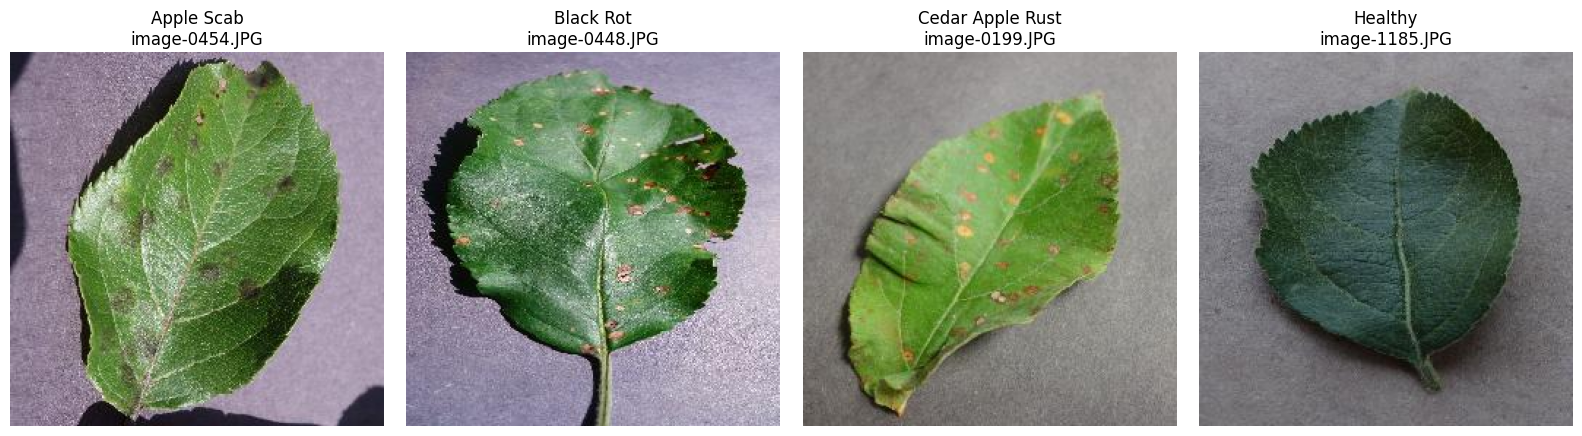

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, cls in zip(axes, WEBAPP_LABELS):
    img_path = sorted((TEST_DIR / cls).iterdir())[0]
    ax.imshow(Image.open(img_path))
    ax.set_title(f"{cls}\n{img_path.name}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 4 — Build the model and load the checkpoint (webapp.py lines 13–18)

Exactly as the author's deployed webapp: `torchvision.models.googlenet()` with the final `fc` replaced by `nn.Linear(in_features, 4)`, then `load_state_dict(..., strict=False)` and `model.eval()`. We additionally report missing/unexpected keys so checkpoint/model agreement is verifiable. (`init_weights=False` only skips re-initializing weights that are immediately overwritten by the checkpoint.)

**日本語:** webapp.pyと同一の構成（GoogLeNet＋4クラスfc、strict=Falseで読み込み、eval）でモデルを構築し、チェックポイントとのキー不一致がないかを確認します。

In [ ]:
model = models.googlenet(init_weights=False)  # architecture only; weights come from the checkpoint
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(WEBAPP_LABELS))  # webapp.py: fc -> 4 outputs

state = torch.load(CKPT_PATH, map_location="cpu")
result = model.load_state_dict(state, strict=False)  # strict=False exactly as webapp.py
print("missing keys:", list(result.missing_keys))
print("unexpected keys:", list(result.unexpected_keys))

model.eval()
model.to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"GoogLeNet ready on {device}; {n_params/1e6:.2f}M parameters")

missing keys: ['aux1.conv.conv.weight', 'aux1.conv.bn.weight', 'aux1.conv.bn.bias', 'aux1.conv.bn.running_mean', 'aux1.conv.bn.running_var', 'aux1.fc1.weight', 'aux1.fc1.bias', 'aux1.fc2.weight', 'aux1.fc2.bias', 'aux2.conv.conv.weight', 'aux2.conv.bn.weight', 'aux2.conv.bn.bias', 'aux2.conv.bn.running_mean', 'aux2.conv.bn.running_var', 'aux2.fc1.weight', 'aux2.fc1.bias', 'aux2.fc2.weight', 'aux2.fc2.bias']
unexpected keys: []
GoogLeNet ready on cpu; 11.98M parameters


### Minimal inference demo: one image per class

We run the author's prediction function (`transform_image` + `forward` + argmax) on one test image per class, and overlay the **ground-truth label (author annotation, folder name)** and the **model prediction** on the original images. Correct predictions are labeled green, mistakes red.

**日本語:** 各クラス1枚を推論します。画像上には著者アノテーション（フォルダ名＝正解）とモデル予測を重ねて表示します（緑=一致、赤=不一致）。

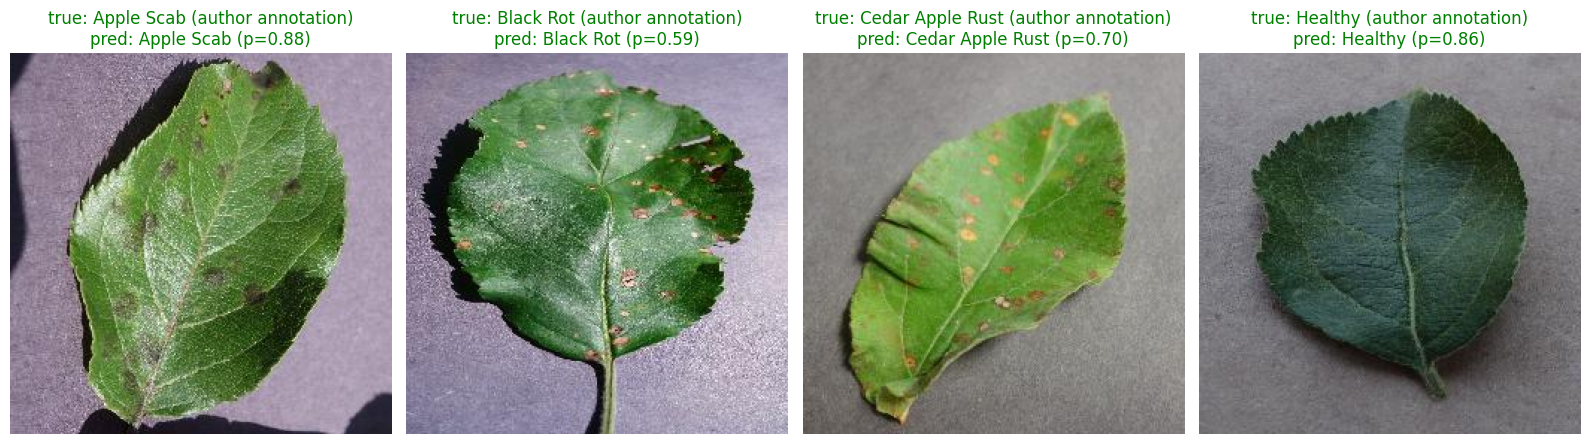

In [ ]:
import torch.nn.functional as F

@torch.no_grad()
def predict_path(img_path):
    """webapp.py get_prediction: author transform -> forward -> argmax."""
    tensor = test_transform(Image.open(img_path).convert("RGB")).unsqueeze(0).to(device)
    logits = model(tensor)
    probs = F.softmax(logits, dim=1)[0]
    conf, idx = probs.max(0)
    return WEBAPP_LABELS[idx], float(conf)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, cls in zip(axes, WEBAPP_LABELS):
    img_path = sorted((TEST_DIR / cls).iterdir())[0]
    pred, conf = predict_path(img_path)
    ax.imshow(Image.open(img_path))
    ok = pred == cls
    ax.set_title(f"true: {cls} (author annotation)\npred: {pred} (p={conf:.2f})",
                 color="green" if ok else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 5 — Evaluate the full author test split

Following the author's own evaluation style (`model train and test.py` confusion-matrix block, applied here to their `test` split): iterate the ImageFolder loader with the author transform, accumulate a 4×4 confusion matrix (rows = true author label, columns = prediction), batch size 4 as in the training script, `torch.no_grad()`, eval mode.

**日本語:** 著者のコードと同様の混同行列評価を、同梱テスト分割全件に対して実行します（バッチ4、no_grad、eval）。

In [ ]:
import time
from torch.utils.data import DataLoader

loader = DataLoader(test_set, batch_size=4, shuffle=False, num_workers=2)
NB_CLASSES = 4  # author: nb_classes = 4
confusion = torch.zeros(NB_CLASSES, NB_CLASSES, dtype=torch.int64)

t0 = time.time()
n_seen = 0
with torch.no_grad():
    for inputs, labels in loader:
        outputs = model(inputs.to(device))
        preds = outputs.argmax(dim=1).cpu()
        for t, p in zip(labels.view(-1), preds.view(-1)):
            confusion[t.long(), p.long()] += 1
        n_seen += inputs.size(0)
elapsed = time.time() - t0

overall_acc = confusion.diag().sum().item() / confusion.sum().item()
print(f"evaluated {n_seen} test images in {elapsed:.1f}s on {device}")
print(f"overall test accuracy: {overall_acc:.4f}")

evaluated 634 test images in 76.7s on cpu
overall test accuracy: 0.9243


### Confusion matrix and per-class results

The confusion matrix is drawn from the counts computed above (a graph created for this notebook, following the author's evaluation block; the paper's own figures were not readable through authorized routes). Results are also exported to CSV inside Colab.

**日本語:** 上で計算した混同行列を可視化し、クラス別精度を表とCSV（Colab内保存）に出力します。この図は本ノートブック用に作成したものであり、論文図の再現ではありません。

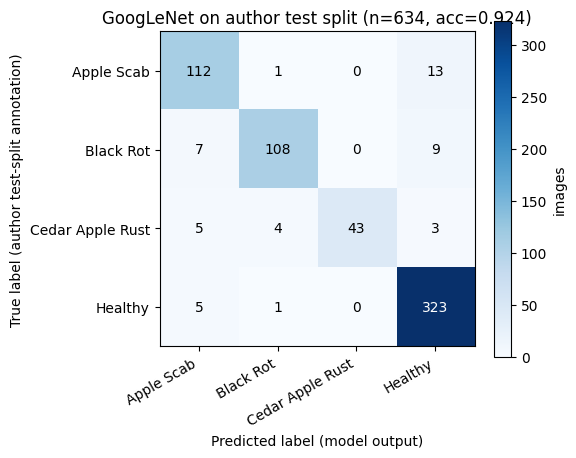

      true_class  n_images  correct  accuracy
      Apple Scab       126      112  0.888889
       Black Rot       124      108  0.870968
Cedar Apple Rust        55       43  0.781818
         Healthy       329      323  0.981763
CSV saved to /content/googlenet_test_results.csv


In [ ]:
import numpy as np

cm = confusion.numpy()
per_class_acc = {c: cm[i, i] / cm[i].sum() for i, c in enumerate(WEBAPP_LABELS)}

fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NB_CLASSES), WEBAPP_LABELS, rotation=30, ha="right")
ax.set_yticks(range(NB_CLASSES), WEBAPP_LABELS)
ax.set_xlabel("Predicted label (model output)")
ax.set_ylabel("True label (author test-split annotation)")
for i in range(NB_CLASSES):
    for j in range(NB_CLASSES):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title(f"GoogLeNet on author test split (n={int(cm.sum())}, acc={overall_acc:.3f})")
fig.colorbar(im, ax=ax, label="images")
plt.tight_layout()
plt.show()

import pandas as pd
rows = [{"true_class": c, "n_images": int(cm[i].sum()),
         "correct": int(cm[i, i]), "accuracy": per_class_acc[c]}
        for i, c in enumerate(WEBAPP_LABELS)]
results_df = pd.DataFrame(rows)
results_df.to_csv("/content/googlenet_test_results.csv", index=False)
print(results_df.to_string(index=False))
print("CSV saved to /content/googlenet_test_results.csv")

## Interpretation, limitations, and validation record / 解釈と限界

- **What this verifies:** the author-released checkpoint runs and produces the paper's task output (4-class apple leaf disease prediction) under the author's own preprocessing, evaluated on the author's own held-out test split. Predictions and accuracies shown are from this executed run.
- **What this does NOT verify:** paper-reported metrics are unknown here (the article full text was inaccessible through authorized routes — Springer challenge pages; no Europe PMC record). A one-repo test-split run is not verification of the paper's dataset-level claims. Training was not re-run (inference-first policy).
- **Adaptations:** modern Colab torch/torchvision instead of the pinned torch 1.11 (same API); checkpoint loading reported `missing/unexpected keys` above for transparency; batch size 4 kept from the author's script.
- **日本語:** 本ノートブックは著者公開チェックポイントが著者自身の前処理・テスト分割で機能することを検証します。論文本文が取得できないため論文記載精度との比較はできず、学習の再実行も対象外です。ただし実行値はすべてこの実行結果です。

## References

1. Wani, Z.A., Zahoor, U., Shah, Z.A. (2024). Apple Leaf Disease Detection Using Transfer Learning. *Annals of Data Science* 12(1), 213–222. https://doi.org/10.1007/s40745-024-00555-y
2. Author repository (MIT): https://github.com/ozair-wani/Apple-leaf-disease-detection @ `947dae59b4e1d053b4235b0fae1823d51fbf85d4` — `webapp.py`, `model train and test.py`, `webapp and code/Best Model/t_googlenet.pth`, `webapp and code/Dataset/test/`.
3. Dataset provenance (author note `webapp and code/Dataset source`): PlantVillage-derived — https://github.com/spMohanty/PlantVillage-Dataset
4. License: MIT (c) 2022 ozair ahmad wani, umer zahoor, zubair ahmad shah.